# División del dataset — ISIC 2020

**CNNs vs Transformers para clasificación de melanoma**

1. **Análisis exploratorio:** entender el desbalance de clases, la estructura por paciente y los metadatos, porque cada uno condiciona decisiones del entrenamiento.
2. **División train / validación / prueba (70 / 15 / 15):** estratificada por clase y **agrupada por paciente**, que será la misma para los tres modelos (mismo protocolo experimental).

In [1]:
## Standard libraries
import os
import json
import numpy as np
import pandas as pd

## Imágenes
from PIL import Image

## Imports for plotting
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('svg', 'pdf') # For export
import seaborn as sns
sns.set()

## División de datos
from sklearn.model_selection import StratifiedGroupKFold

## Progress bar
from tqdm.notebook import tqdm

In [2]:
DATASET_PATH = r"C:\datasets\isic2020"
IN_CSV       = os.path.join(DATASET_PATH, "train_256.csv")
OUT_CSV      = os.path.join(DATASET_PATH, "train_256_split.csv")
SEED         = 42

# Colores fijos para todo el proyecto
COLOR_BENIGN, COLOR_MALIGNANT = "#2a78d6", "#eb6834"
SPLIT_COLORS = {"train": "#2a78d6", "val": "#eb6834", "test": "#1baf7a"}

df = pd.read_csv(IN_CSV)
print(df.shape)
df.head()

(32701, 12)


,image_name,patient_id,lesion_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target,orig_width,orig_height,image_path
0,ISIC_2637011,IP_7279968,IL_7972535,male,45.0,head/neck,unknown,benign,0,6000,4000,C:\datasets\isic2020\img256\ISIC_2637011.jpg
1,ISIC_0015719,IP_3075186,IL_4649854,female,45.0,upper extremity,unknown,benign,0,6000,4000,C:\datasets\isic2020\img256\ISIC_0015719.jpg
2,ISIC_0052212,IP_2842074,IL_9087444,female,50.0,lower extremity,nevus,benign,0,1872,1053,C:\datasets\isic2020\img256\ISIC_0052212.jpg
3,ISIC_0068279,IP_6890425,IL_4255399,female,45.0,head/neck,unknown,benign,0,1872,1053,C:\datasets\isic2020\img256\ISIC_0068279.jpg
4,ISIC_0074268,IP_8723313,IL_6898037,female,55.0,upper extremity,unknown,benign,0,6000,4000,C:\datasets\isic2020\img256\ISIC_0074268.jpg


### Valores faltantes

Solo los metadatos tienen faltantes, y son pocos. No afectan a la clasificación por imagen; los conservamos como "desconocido" para el análisis.

In [3]:
missing = df.isna().sum()
missing[missing > 0].to_frame("faltantes").assign(porcentaje=lambda t: (t.faltantes / len(df) * 100).round(2))

,faltantes,porcentaje
sex,41,0.13
age_approx,44,0.13
anatom_site_general_challenge,526,1.61


## 1. Distribución de clases

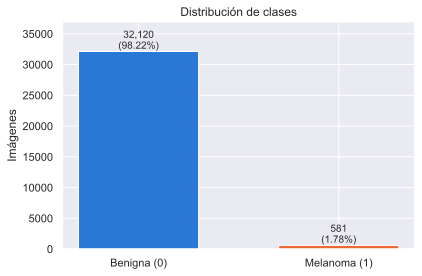

Relación benigna:melanoma = 55.3 : 1
Accuracy de un modelo que SIEMPRE predice 'benigna': 98.22%


In [4]:
counts = df.target.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Benigna (0)", "Melanoma (1)"], counts.values, color=[COLOR_BENIGN, COLOR_MALIGNANT], width=0.6)
for b, n in zip(bars, counts.values):
    ax.annotate(f"{n:,}\n({n / len(df):.2%})", (b.get_x() + b.get_width() / 2, n), ha="center", va="bottom", fontsize=10)
ax.set_ylabel("Imágenes")
ax.set_ylim(0, counts.max() * 1.15)
ax.set_title("Distribución de clases")
plt.tight_layout()
plt.show()

ratio = counts[0] / counts[1]
print(f"Relación benigna:melanoma = {ratio:.1f} : 1")
print(f"Accuracy de un modelo que SIEMPRE predice 'benigna': {counts[0] / len(df):.2%}")

## 2. Diagnósticos

La etiqueta binaria `target` agrupa diagnósticos más finos. La mayoría de las lesiones benignas no tiene diagnóstico específico (`unknown`).

In [5]:
diag = df.groupby("diagnosis").agg(imagenes=("target", "size"), target=("target", "max")).sort_values("imagenes", ascending=False)
diag["porcentaje"] = (diag.imagenes / len(df) * 100).round(2)
diag

,imagenes,target,porcentaje
diagnosis,,,
unknown,26706,0,81.67
nevus,5191,0,15.87
melanoma,581,1,1.78
seborrheic keratosis,135,0,0.41
lentigo NOS,44,0,0.13
lichenoid keratosis,35,0,0.11
solar lentigo,7,0,0.02
atypical melanocytic proliferation,1,0,0.00
cafe-au-lait macule,1,0,0.00


## 3. Estructura por paciente

Cada paciente aporta varias imágenes de **distintas lesiones**. Las lesiones de una misma persona comparten tipo de piel, cámara e iluminación, así que si un paciente aparece en entrenamiento y en prueba, el modelo puede "reconocer al paciente" y las métricas salen infladas. Por eso la división debe hacerse **por paciente**.

Pacientes: 2,056
Imágenes por paciente: mediana 12, media 15.9, máx 115
Pacientes con al menos un melanoma: 428 (20.8%)
Lesiones únicas: 32,693 (prácticamente una imagen por lesión)


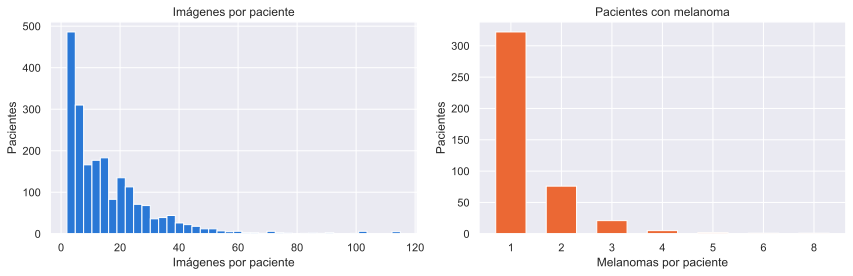

In [6]:
per_patient = df.groupby("patient_id").agg(imagenes=("target", "size"), melanomas=("target", "sum"))
print(f"Pacientes: {len(per_patient):,}")
print(f"Imágenes por paciente: mediana {per_patient.imagenes.median():.0f}, "
      f"media {per_patient.imagenes.mean():.1f}, máx {per_patient.imagenes.max()}")
print(f"Pacientes con al menos un melanoma: {(per_patient.melanomas > 0).sum()} "
      f"({(per_patient.melanomas > 0).mean():.1%})")
print(f"Lesiones únicas: {df.lesion_id.nunique():,} (prácticamente una imagen por lesión)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(per_patient.imagenes, bins=40, color=COLOR_BENIGN, edgecolor="white")
axes[0].set_xlabel("Imágenes por paciente")
axes[0].set_ylabel("Pacientes")
axes[0].set_title("Imágenes por paciente")

mel = per_patient.melanomas[per_patient.melanomas > 0].value_counts().sort_index()
axes[1].bar(mel.index.astype(str), mel.values, color=COLOR_MALIGNANT, width=0.6)
axes[1].set_xlabel("Melanomas por paciente")
axes[1].set_ylabel("Pacientes")
axes[1].set_title("Pacientes con melanoma")
plt.tight_layout()
plt.show()

## 4. Metadatos y riesgo de melanoma

Aunque nuestros modelos solo usarán la imagen, los metadatos ayudan a describir la población y se mencionarán como posible mejora (**multimodalidad**) en el análisis final.

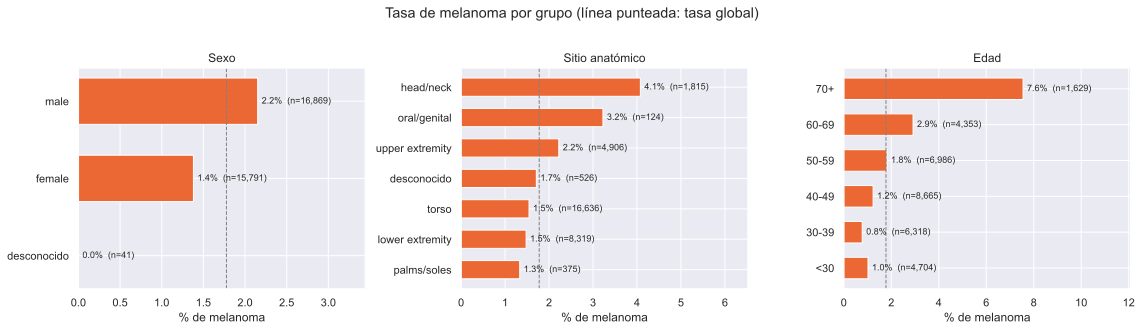

In [7]:
def malignancy_rate(col, order=None):
    t = df.assign(**{col: df[col].fillna("desconocido")}).groupby(col).target.agg(["size", "mean"])
    t.columns = ["imagenes", "tasa"]
    return t.loc[order] if order is not None else t.sort_values("tasa")

age_bins = pd.cut(df.age_approx, bins=[0, 30, 40, 50, 60, 70, 90], labels=["<30", "30-39", "40-49", "50-59", "60-69", "70+"])
df["age_group"] = age_bins.astype(str).replace("nan", "desconocido")

panels = [("sex", "Sexo", None),
          ("anatom_site_general_challenge", "Sitio anatómico", None),
          ("age_group", "Edad", ["<30", "30-39", "40-49", "50-59", "60-69", "70+"])]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (col, title, order) in zip(axes, panels):
    t = malignancy_rate(col, order)
    ax.barh(t.index.astype(str), t.tasa * 100, color=COLOR_MALIGNANT, height=0.6)
    for y, (rate, n) in enumerate(zip(t.tasa, t.imagenes)):
        ax.annotate(f"{rate:.1%}  (n={n:,})", (rate * 100, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
    ax.set_xlim(0, t.tasa.max() * 100 * 1.6)
    ax.axvline(df.target.mean() * 100, color="gray", ls="--", lw=1)
    ax.set_xlabel("% de melanoma")
    ax.set_title(title)
plt.suptitle("Tasa de melanoma por grupo (línea punteada: tasa global)", y=1.02)
plt.tight_layout()
plt.show()

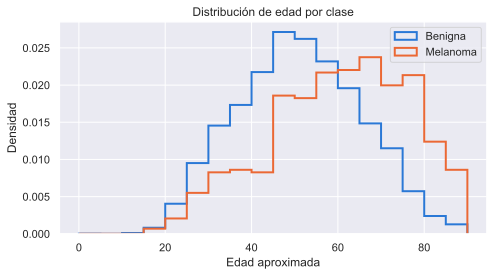

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.arange(0, 95, 5)
for label, name, color in [(0, "Benigna", COLOR_BENIGN), (1, "Melanoma", COLOR_MALIGNANT)]:
    ax.hist(df.loc[df.target == label, "age_approx"].dropna(), bins=bins, density=True,
            histtype="step", lw=2, color=color, label=name)
ax.set_xlabel("Edad aproximada")
ax.set_ylabel("Densidad")
ax.set_title("Distribución de edad por clase")
ax.legend()
plt.tight_layout()
plt.show()

El riesgo de melanoma **aumenta claramente con la edad** y es algo mayor en hombres y en cabeza/cuello. Son patrones conocidos clínicamente, lo que da confianza en las etiquetas.

## 5. Resolución original y posibles atajos (*shortcut learning*)

Las imágenes vienen de distintos equipos y hospitales. Si la proporción de melanomas cambia mucho según la cámara, un modelo podría aprender a reconocer **el equipo** en lugar de **la lesión**. No podemos eliminar este sesgo, pero lo dejamos documentado para interpretar los mapas de Grad-CAM.

In [9]:
df["resolution"] = df.orig_width.astype(str) + "×" + df.orig_height.astype(str)
top_res = df.resolution.value_counts().head(8).index
res_rate = df[df.resolution.isin(top_res)].groupby("resolution").target.agg(imagenes="size", melanomas="sum", tasa="mean")
res_rate["tasa"] = (res_rate.tasa * 100).round(2)
res_rate.sort_values("imagenes", ascending=False)

,imagenes,melanomas,tasa
resolution,,,
6000×4000,14285,21,0.15
1872×1053,7534,130,1.73
640×480,4147,91,2.19
5184×3456,3412,72,2.11
3264×2448,1483,92,6.20
4288×2848,729,47,6.45
2592×1936,674,71,10.53
3888×2592,140,8,5.71


> **Hallazgo importante:** la tasa de melanoma varía muchísimo según la resolución de origen: las imágenes de 6000×4000 casi nunca son melanoma (~0.15 %), mientras que las de 2592×1936 lo son en ~10 %. Esto es una señal de riesgo de *shortcut learning*. Al redimensionar a 256 px se pierde la resolución explícita, pero el estilo de cada equipo (color, viñeteado, nitidez) sigue presente en la imagen.

## 6. Estadísticas de color

Comparamos la media y desviación estándar RGB del dataset con las de ImageNet. Como usaremos modelos **preentrenados en ImageNet**, normalizaremos con las estadísticas de ImageNet (las que esperan los pesos), pero conviene saber cuánto difieren: las imágenes dermatoscópicas son más rojizas y con menos variación que las fotos naturales.

In [10]:
sample = df.sample(2000, random_state=SEED)
pix_sum, pix_sq, n_pix = np.zeros(3), np.zeros(3), 0
for path in tqdm(sample.image_path):
    x = np.asarray(Image.open(path), dtype=np.float64) / 255.0
    pix_sum += x.sum(axis=(0, 1))
    pix_sq  += (x ** 2).sum(axis=(0, 1))
    n_pix   += x.shape[0] * x.shape[1]
isic_mean = pix_sum / n_pix
isic_std  = np.sqrt(pix_sq / n_pix - isic_mean ** 2)

pd.DataFrame({"ISIC 2020 media": isic_mean, "ISIC 2020 std": isic_std,
              "ImageNet media": [0.485, 0.456, 0.406], "ImageNet std": [0.229, 0.224, 0.225]},
             index=["R", "G", "B"]).round(3)

  0%|          | 0/2000 [00:00<?, ?it/s]

,ISIC 2020 media,ISIC 2020 std,ImageNet media,ImageNet std
R,0.797,0.150,0.485,0.229
G,0.606,0.179,0.456,0.224
B,0.576,0.203,0.406,0.225


## 7. División train / validación / prueba

Usamos `StratifiedGroupKFold` con **20 folds**:
- **Agrupado** por `patient_id`: todas las imágenes de un paciente quedan en el mismo conjunto.
- **Estratificado** por `target`: cada conjunto conserva ~1.8 % de melanomas.

Asignamos los folds 0–2 a prueba (15 %), 3–5 a validación (15 %) y 6–19 a entrenamiento (70 %). Guardamos también el número de fold por si después se quiere hacer validación cruzada.

In [ ]:
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED) ## Divide los datos en 20 folds estratificados por la variable 'target' y agrupados por 'patient_id'. 
df["fold"] = -1
for fold, (_, idx) in enumerate(sgkf.split(df, y=df.target, groups=df.patient_id)):
    df.loc[idx, "fold"] = fold

df["split"] = np.select([df.fold <= 2, df.fold <= 5], ["test", "val"], default="train")

summary = df.groupby("split").agg(imagenes=("target", "size"), pacientes=("patient_id", "nunique"),
                                  melanomas=("target", "sum"), pct_melanoma=("target", "mean"))
summary["pct_imagenes"] = summary.imagenes / len(df) * 100
summary["pct_melanoma"] = summary.pct_melanoma * 100
summary.loc[["train", "val", "test"]].round(2)

,imagenes,pacientes,melanomas,pct_melanoma,pct_imagenes
split,,,,,
train,22889,1442,404,1.77,69.99
val,4910,305,89,1.81,15.01
test,4902,309,88,1.80,14.99


### Verificación

1. Ningún paciente aparece en más de un conjunto.
2. La distribución de edad, sexo y sitio anatómico es similar entre conjuntos.

In [12]:
patients = {s: set(df.loc[df.split == s, "patient_id"]) for s in ["train", "val", "test"]}
assert not (patients["train"] & patients["val"]),  "Pacientes compartidos train/val"
assert not (patients["train"] & patients["test"]), "Pacientes compartidos train/test"
assert not (patients["val"]   & patients["test"]), "Pacientes compartidos val/test"
print("OK: ningún paciente compartido entre conjuntos")

meta = pd.concat({
    "edad media":     df.groupby("split").age_approx.mean().round(1),
    "% mujeres":      df.groupby("split").sex.apply(lambda s: (s == "female").mean() * 100).round(1),
    "% torso":        df.groupby("split").anatom_site_general_challenge.apply(lambda s: (s == "torso").mean() * 100).round(1),
    "% extremidades": df.groupby("split").anatom_site_general_challenge.apply(lambda s: s.str.contains("extremity", na=False).mean() * 100).round(1),
}, axis=1)
meta.loc[["train", "val", "test"]]

OK: ningún paciente compartido entre conjuntos


,edad media,% mujeres,% torso,% extremidades
split,,,,
train,49.2,48.9,51.3,40.3
val,49.0,46.7,48.7,40.7
test,46.6,47.2,50.9,40.8


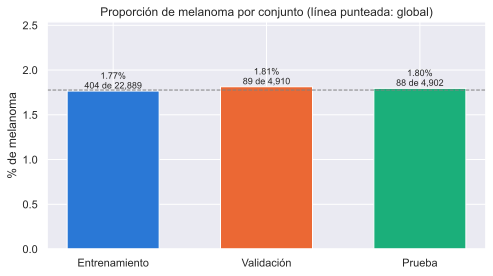

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
order = ["train", "val", "test"]
x = np.arange(len(order))
ax.bar(x, summary.loc[order, "pct_melanoma"], color=[SPLIT_COLORS[s] for s in order], width=0.6)
for i, s in enumerate(order):
    ax.annotate(f"{summary.loc[s, 'pct_melanoma']:.2f}%\n{int(summary.loc[s, 'melanomas'])} de {int(summary.loc[s, 'imagenes']):,}",
                (i, summary.loc[s, "pct_melanoma"]), ha="center", va="bottom", fontsize=9)
ax.axhline(df.target.mean() * 100, color="gray", ls="--", lw=1)
ax.set_xticks(x, ["Entrenamiento", "Validación", "Prueba"])
ax.set_ylabel("% de melanoma")
ax.set_ylim(0, summary.pct_melanoma.max() * 1.4)
ax.set_title("Proporción de melanoma por conjunto (línea punteada: global)")
plt.tight_layout()
plt.show()

### Peso de la clase positiva

Para la pérdida ponderada (`BCEWithLogitsLoss(pos_weight=...)`) usaremos la relación negativos/positivos **del conjunto de entrenamiento**.

no detectar un melanoma es 56 veces más grave que equivocarse con una lesión benigna. es por eso que multiplicamos los errores encontrados por 55.7 que da como resultado

In [14]:
train = df[df.split == "train"]
pos_weight = (train.target == 0).sum() / (train.target == 1).sum()
print(f"pos_weight = {pos_weight:.1f}")

pos_weight = 55.7


## 8. Guardar

In [15]:
cols = ["image_name", "patient_id", "lesion_id", "sex", "age_approx", "anatom_site_general_challenge",
        "diagnosis", "target", "orig_width", "orig_height", "image_path", "fold", "split"]
df[cols].to_csv(OUT_CSV, index=False)

stats = {"isic_mean": isic_mean.round(4).tolist(), "isic_std": isic_std.round(4).tolist(),
         "pos_weight": round(float(pos_weight), 2), "seed": SEED}
with open(os.path.join(DATASET_PATH, "dataset_stats.json"), "w") as f:
    json.dump(stats, f, indent=2)

print("Guardado:", OUT_CSV, df[cols].shape)
print(stats)

Guardado: C:\datasets\isic2020\train_256_split.csv (32701, 13)
{'isic_mean': [0.7966, 0.6056, 0.5757], 'isic_std': [0.1504, 0.1791, 0.2032], 'pos_weight': 55.66, 'seed': 42}
